# Part 1 — Assigning Users to Groups: `md5(userId + salt) % 2`

Every AB testing platform has one basic question at its core: **"Which variant will this user see?"**

The most common answer in the industry is simple. We join the user's ID with a *salt*, hash the result, and split the hash into groups:

```
md5(userId + salt) % 2  →  0: A, 1: B
```

In this notebook we will look at this approach step by step, with small iterations:

1. **v1** — The simplest version: `md5(userId + salt) % 2`
2. Is the split really 50/50? → **SRM (Sample Ratio Mismatch)** test
3. Does the hash really behave like a random split? → **A/A simulation**
4. Why `md5` and not Python's built-in `hash()`? → **Determinism**
5. What is the salt for? → **Independence between experiments**
6. Testing the assignment with an A/A test on CR and GMV → **Noise band and 2,000 A/A tests**

Our goal is a solid assignment function. In the next parts, we will build the analytics engine on top of it.

In [1]:
import hashlib
import subprocess
import sys
import timeit
import uuid

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

N_USERS = 100_000
rng = np.random.default_rng(42)

# A clean style for the charts
plt.rcParams.update({
    "figure.figsize": (8, 3.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
BLUE, ORANGE = "#2a78d6", "#eb6834"

## The user base

In e-commerce we usually see two types of IDs:

- **Registered users**: sequential numeric IDs from the database (`1, 2, 3, ...`)
- **Anonymous users**: UUIDs created as a cookie or device ID

We will test both. Sequential IDs are important because a bad hash function can create patterns with them.

In [2]:
sequential_ids = [str(i) for i in range(1, N_USERS + 1)]
uuid_ids = [str(uuid.UUID(bytes=rng.bytes(16), version=4)) for _ in range(N_USERS)]

sequential_ids[:3], uuid_ids[:3]

(['1', '2', '3'],
 ['8826d916-cdfb-41c6-81ff-91a761565a70',
  '2416da6e-c212-4ddb-8d88-00160eb686b2',
  'eb819333-b501-4c18-8c53-c786ed62c2f9'])

## Iteration 1 — The simplest version

`md5` gives a 128-bit output. We turn it into an integer, take `% 2`, and put the user into group A or B.

In [3]:
def assign_v1(user_id: str, salt: str) -> str:
    digest = hashlib.md5((user_id + salt).encode()).hexdigest()
    return "A" if int(digest, 16) % 2 == 0 else "B"


SALT = "checkout_button_color"

df = pd.DataFrame({
    "sequential": [assign_v1(u, SALT) for u in sequential_ids],
    "uuid": [assign_v1(u, SALT) for u in uuid_ids],
})

df.apply(pd.Series.value_counts)

,sequential,uuid
B,50057,50006
A,49943,49994


The result is not exactly 50,000 / 50,000 — and **it should not be**. If every user behaves like an independent coin flip, the number of users in a group follows a Binomial(N, 0.5) distribution. Its standard deviation is `√N / 2 ≈ 158`.

So the real question is: **is the difference we see inside this normal random variation?**

## Iteration 2 — SRM (Sample Ratio Mismatch) check

We compare the observed counts with the expected ratios using a **chi-square goodness-of-fit test**. SRM is the first health check we should run, before we analyse any experiment result. If the split is broken, a difference in the metrics may come from a bug in the assignment, not from the change we are testing.

The industry usually uses a threshold of `p < 0.001` for SRM. Many experiments are monitored all the time, so a strict threshold helps to avoid false alarms.

In [4]:
def srm_check(observed_counts, expected_ratios, alpha=0.001):
    observed = np.asarray(observed_counts, dtype=float)
    expected = observed.sum() * np.asarray(expected_ratios, dtype=float)
    chi2, p_value = stats.chisquare(observed, expected)
    return {"chi2": round(float(chi2), 3), "p_value": round(float(p_value), 4), "srm": bool(p_value < alpha)}


for col in df.columns:
    counts = df[col].value_counts().reindex(["A", "B"])
    print(f"{col:>10}: {counts.to_dict()} → {srm_check(counts, [0.5, 0.5])}")

sequential: {'A': 49943, 'B': 50057} → {'chi2': 0.13, 'p_value': 0.7185, 'srm': False}
      uuid: {'A': 49994, 'B': 50006} → {'chi2': 0.001, 'p_value': 0.9697, 'srm': False}


## Iteration 3 — A/A simulation: does the hash behave like random?

Looking at a single salt is not enough. If the hash function is good, **every split with a different salt should behave like an independent random split**. In that case, the p-values of the SRM test are **uniformly distributed between 0 and 1**, and about 5% of them are below `0.05`.

Let's try it with 500 different salts (in other words, 500 different "experiments"). To compare, we also add a bad method on purpose: `int(userId) % 2` (no salt, no hash).

In [5]:
N_SIM_USERS = 10_000
N_SALTS = 500
sim_users = sequential_ids[:N_SIM_USERS]

p_values = []
for i in range(N_SALTS):
    salt = f"experiment_{i}"
    n_b = sum(int(hashlib.md5((u + salt).encode()).hexdigest(), 16) % 2 for u in sim_users)
    p_values.append(stats.chisquare([N_SIM_USERS - n_b, n_b]).pvalue)
p_values = np.array(p_values)

# Bad method: the result is the same in every "experiment" because there is no salt
naive_n_b = sum(int(u) % 2 for u in sim_users)
naive_p = stats.chisquare([N_SIM_USERS - naive_n_b, naive_n_b]).pvalue

print(f"md5 + salt  → share of p < 0.05: {np.mean(p_values < 0.05):.1%}  (expected ≈ 5%)")
print(f"Kolmogorov-Smirnov (is it uniform?): p = {stats.kstest(p_values, 'uniform').pvalue:.3f}")
print(f"int(id) % 2 → the same split in every experiment, p = {naive_p}  (suspiciously perfect)")

md5 + salt  → share of p < 0.05: 3.8%  (expected ≈ 5%)


Kolmogorov-Smirnov (is it uniform?): p = 0.951
int(id) % 2 → the same split in every experiment, p = 1.0  (suspiciously perfect)


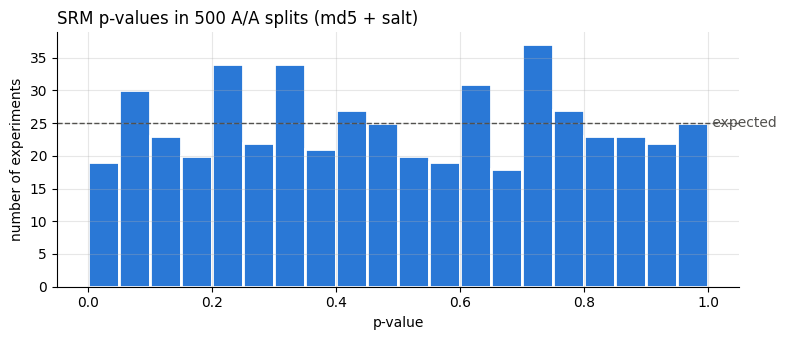

In [6]:
fig, ax = plt.subplots()
ax.hist(p_values, bins=20, range=(0, 1), color=BLUE, edgecolor="white", linewidth=2)
ax.axhline(N_SALTS / 20, color="#52514e", linestyle="--", linewidth=1)
ax.text(1.0, N_SALTS / 20, " expected", va="center", color="#52514e")
ax.set_title("SRM p-values in 500 A/A splits (md5 + salt)", loc="left")
ax.set_xlabel("p-value")
ax.set_ylabel("number of experiments")
plt.tight_layout()
plt.show()

The histogram is almost flat: md5 + salt behaves like an independent random split for each experiment.

`int(id) % 2`, on the other hand, gives **exactly** 5000/5000. This looks good at first, but it hides two serious problems:

- **The same users are in group B in every experiment**: the experiments are not independent of each other. For example, if one experiment still affects users after it ends (a *carry-over effect*), all of those users land in the same group of the next experiment and bias its result.
- **Correlation with the ID**: if the last bit of the ID is related to something (for example, a system that gives even IDs to one source and odd IDs to another), the groups are no longer equal.

## Iteration 4 — Determinism: why not Python's `hash()`?

The most important property of an assignment function is **determinism**. The same user, in the same experiment, must see the same group on every request, on every server and in every language (Java on the backend, JS on the frontend, Python for analysis...). Thanks to this, we **don't need to store the assignment** anywhere — we can calculate it again whenever we need it. It also means we can assign users retroactively to data from *before* the experiment started; we will use this in the next part.

Python's built-in `hash()` function uses a **different random seed in every process** for strings (`PYTHONHASHSEED`). Let's see this in separate processes:

In [7]:
snippet = "print(hash('user_42' + 'checkout_button_color') % 2)"
for run in range(1, 6):
    out = subprocess.run([sys.executable, "-c", snippet], capture_output=True, text=True).stdout.strip()
    print(f"process {run}: hash() → {out}   |   md5 → {assign_v1('user_42', 'checkout_button_color')}")

process 1: hash() → 1   |   md5 → B
process 2: hash() → 0   |   md5 → B


process 3: hash() → 1   |   md5 → B
process 4: hash() → 0   |   md5 → B
process 5: hash() → 0   |   md5 → B


In [8]:
# With md5, the same user gets the same group on every call
assert all(assign_v1(u, SALT) == g for u, g in zip(sequential_ids, df["sequential"]))
print("Deterministic ✔")

Deterministic ✔


> **Note:** md5 is broken as a cryptographic function, but here we don't need security. We need **a good distribution and portability**, and md5 is in the standard library of almost every language. When performance is critical, fast non-cryptographic hashes like MurmurHash3 or xxHash are also popular (for example, GrowthBook uses FNV-1a and Optimizely uses MurmurHash).

In [9]:
n = 200_000
t = timeit.timeit(lambda: hashlib.md5(b"123456:checkout_button_color").hexdigest(), number=n)
print(f"md5: {t / n * 1e6:.2f} µs per assignment")

md5: 0.33 µs per assignment


## Iteration 5 — What is the salt for? Independence between experiments

When we run many experiments, we want group membership in one experiment to be **unrelated** to group membership in another one. If two experiments use the same salt and the same allocation, they assign exactly the same users to the same groups. Then:

- **Experiments running at the same time:** everyone in group B of Experiment 1 is also in group B of Experiment 2. We cannot separate the two effects: Experiment 1's effect is mixed into Experiment 2's result (this is called *confounding*).
- **Experiments running one after another:** if Experiment 1 still affects users after it ends (a *carry-over effect*), all of those users are again in the same group in Experiment 2, and this biases the result.
- In both cases, the same users always see the "new" experiences.

A different salt for each experiment (usually the experiment key or ID) breaks this link. Each group in Experiment 2 gets about the same share of Experiment 1's users, so the other experiment's effect is **balanced between A and B** instead of favouring one group.

Note what a different salt does *not* do: it does not remove interactions between experiments or carry-over effects themselves. Users are still affected by other experiments; the salt only stops these effects from biasing our comparison. Handling real interactions (for example, with mutually exclusive experiments) is a platform design topic for a later part.

Let's compare two scenarios:

In [10]:
def crosstab_for(salt_1, salt_2):
    exp1 = [assign_v1(u, salt_1) for u in sequential_ids]
    exp2 = [assign_v1(u, salt_2) for u in sequential_ids]
    table = pd.crosstab(pd.Series(exp1, name="experiment_1"), pd.Series(exp2, name="experiment_2"))
    _, p, _, _ = stats.chi2_contingency(table)
    return table, p


same_table, same_p = crosstab_for("ab_salt", "ab_salt")
diff_table, diff_p = crosstab_for("checkout_button_color", "free_shipping_banner")

print("Same salt (both experiments use 'ab_salt'):")
display(same_table)
print("Different salts:")
display(diff_table)
print(f"Independence test p-value: {diff_p:.3f}  → the groups are independent")

Same salt (both experiments use 'ab_salt'):


experiment_2,A,B
experiment_1,,
A,50137,0
B,0,49863


Different salts:


experiment_2,A,B
experiment_1,,
A,24996,24947
B,24950,25107


Independence test p-value: 0.519  → the groups are independent


With the same salt, the two experiments make **exactly the same split**: everyone in group B of Experiment 1 is also in group B of Experiment 2. With different salts, each cell is about 25% — the groups are independent of each other.

> **Platform decision:** Instead of letting the user (the person who creates the experiment) choose the salt, we can **generate it automatically from the experiment ID**. This makes the mistake impossible by design. In some cases, though, we want the *same* salt on purpose (for example, for mutually exclusive experiments, or to keep the same users in the second version of an experiment). We will cover this in the configuration management part.

## Iteration 6 — Testing the assignment with an A/A test

Now that we have split our users into two groups, we want to measure the impact of our change. But before that, we need to test the assignment itself. With the SRM check, we already saw that the group sizes are balanced. However, balanced group sizes are not enough: the groups should also behave the same way when nothing is different between them.

The way to check this is an **A/A test**: both groups see exactly the same experience, so any difference we measure is pure noise. This tells us two things: whether our assignment and measurement work correctly, and how big a "lift" can look by chance alone.

In e-commerce, conversion rate (CR) and GMV are two good metrics to start with. At the user level, CR is binary (a user either places an order or not), while GMV is continuous. We will not go into the differences between these two metric types here, but they will be important in later parts.

### A mock dataset

We use the same 100,000 users with the same group assignment. For each user we create two values:

1. **Did the user place an order? (CR)** Every user places an order with a probability of 3%, like a weighted coin flip.
2. **How much did the user spend? (GMV)** If the user placed an order, we give them an order value; otherwise their GMV is 0. Real order values are not evenly distributed: most orders are small or medium, but a few are very large. To create this shape, we use a **log-normal distribution** with a median of 80. It is a common choice for money values, because it has no negative values and a long tail on the right side.

In [11]:
gmv_rng = np.random.default_rng(7)

CR = 0.03                                                       # 3% of users place an order
converted = gmv_rng.random(N_USERS) < CR
order_value = gmv_rng.lognormal(np.log(80), 1.0, N_USERS)       # order value: median 80, long right tail
gmv = np.where(converted, order_value, 0.0)                     # GMV is 0 for users without an order

users = pd.DataFrame({"user_id": sequential_ids, "group": df["sequential"], "gmv": gmv.round(2)})

top_buyers = np.sort(gmv[converted])[::-1]
print(f"{'users':<40}: {N_USERS:,}")
print(f"{'buyers':<40}: {converted.sum():,} ({converted.mean():.1%})")
print(f"{'mean GMV per user':<40}: {gmv.mean():.2f}")
print(f"{'median order value (buyers)':<40}: {np.median(order_value[converted]):.2f}")
print(f"{'largest order':<40}: {gmv.max():.2f}")
print(f"{'share of GMV from the top 10% of buyers':<40}: {top_buyers[: len(top_buyers) // 10].sum() / gmv.sum():.0%}")

users                                   : 100,000
buyers                                  : 2,942 (2.9%)
mean GMV per user                       : 3.80
median order value (buyers)             : 80.27
largest order                           : 2846.33
share of GMV from the top 10% of buyers : 38%


About 97% of users have a GMV of 0. Among the buyers, the top 10% bring 38% of the total GMV, and the largest order is about 35 times the median order. This long tail will be important.

> **Keep in mind:** This dataset is simplified. Each user can place at most one order, and there is no user history: a user's past behaviour tells us nothing about their future behaviour. This is enough for an A/A test, but in the next part we will need users with a history.

### Measuring the difference: a simple z-test

To compare the two groups, we use a **z-test**. We take the difference between the group averages and divide it by its standard error, which is the amount of difference we can expect from random noise alone:

```
z = (mean_B − mean_A) / √(var_A / n_A + var_B / n_B)
```

If |z| is bigger than **1.96** (which is the same as p < 0.05), we call the result "significant". In simple words: the difference should be about two times bigger than the normal noise. The same formula works for both metrics, because CR is the average of 0/1 values and GMV per user is also an average. With thousands of users per group, the difference of the means is almost normally distributed (central limit theorem), even when GMV itself is very skewed.

Next to each lift, we also show the **noise band**: the range where the lift will most likely fall when there is no real effect (about two times the standard error, which depends on the variance and the number of users). If the observed lift is inside the band, we cannot say it is different from noise.

### One A/A test

Let's run one A/A test with our assignment from Iteration 1, for both metrics, once with the first 10,000 users and once with all 100,000 users:

In [12]:
def z_test(a, b):
    # z = difference of the means / standard error of that difference
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    z = (b.mean() - a.mean()) / se
    return z, se


def aa_test(values, in_b):
    a, b = values[~in_b], values[in_b]
    z, se = z_test(a, b)
    lift = (b.mean() / a.mean() - 1) * 100
    band = 1.96 * se / a.mean() * 100      # noise band, as % of the control mean
    p_value = 2 * stats.norm.sf(abs(z))    # two-sided p-value: p < 0.05 is the same as |z| > 1.96
    return lift, band, p_value


in_b = (users["group"] == "B").to_numpy()  # our md5 assignment from Iteration 1
metrics = {"CR": converted.astype(float), "GMV": gmv}

for metric, values in metrics.items():
    for n in [10_000, 100_000]:
        lift, band, p = aa_test(values[:n], in_b[:n])
        status = "inside the band" if abs(lift) < band else "OUTSIDE the band"
        print(f"{metric:<3} {n:>7,} users: lift = {lift:+5.1f}%   noise band = ±{band:4.1f}%   → {status} (p = {p:.3f})")

CR   10,000 users: lift =  +1.7%   noise band = ±22.7%   → inside the band (p = 0.884)
CR  100,000 users: lift =  +4.2%   noise band = ± 7.3%   → inside the band (p = 0.256)
GMV  10,000 users: lift = +42.8%   noise band = ±53.3%   → inside the band (p = 0.115)
GMV 100,000 users: lift =  +1.3%   noise band = ±11.8%   → inside the band (p = 0.826)


All four results are inside their bands, so none of them is significant. But two things stand out.

**First, more users means a narrower band.** For both metrics, the band becomes about 3 to 4.5 times narrower when we go from 10,000 to 100,000 users.

**Second, the metric itself affects the band.** With the same users, GMV's band is about two times wider than CR's. For CR, each user is just 0 or 1. For GMV, we have two kinds of uncertainty: *whether* the user buys, and *how much* they spend. On top of that, a few very large orders can move the average a lot. In statistics, this "how much the values spread from user to user" is called **variance**. The higher the variance of a metric, the wider its noise band. So it is not about the data type itself, but about the variance of the metric.

Variance will be one of the key ideas in this series. In the next parts, we will look at it in more detail and see how we can reduce it to make our experiments more sensitive.

Now look at the GMV result with 10,000 users again. Both groups saw exactly the same thing, but group B shows a **42.8% higher GMV**. Imagine seeing this number on a dashboard: many people would celebrate it. But the noise band shows that, with 10,000 users, a GMV lift up to ±53% can easily come from pure chance.

### One test is not enough

So far, everything looks OK. All four results are inside their noise bands, and none of them is significant. This is exactly what we expect from an A/A test.

But one A/A test is not enough to trust our setup. A single test can look fine just by luck. What we really want to know is: **if we run many A/A tests, how often does our test say "significant" when there is no effect?** If our assignment and our test work correctly, this should happen in about 5% of the tests, because p < 0.05 means exactly that.

### 2,000 A/A tests

Iteration 3 showed that md5 + salt behaves like a random split. So, to keep it fast, we repeat the A/A test 2,000 times with a random 50/50 split each time (like 2,000 experiments with different salts). For each test, we record whether the result was "significant" and how big the observed lift was:

In [13]:
sim_rng = np.random.default_rng(2026)
N_SIMS = 2_000

rows, lifts = [], {}
for metric, values in metrics.items():
    for n in [10_000, 100_000]:
        results = np.array([aa_test(values[:n], sim_rng.random(n) < 0.5) for _ in range(N_SIMS)])
        lifts[(metric, n)] = results[:, 0]
        low, high = np.percentile(results[:, 0], [2.5, 97.5])
        rows.append({
            "metric": metric,
            "users": f"{n:,}",
            "false positive rate (p < 0.05)": f"{np.mean(results[:, 2] < 0.05):.1%}",
            "95% of lifts": f"{low:+.1f}% … {high:+.1f}%",
        })

pd.DataFrame(rows)

,metric,users,false positive rate (p < 0.05),95% of lifts
0,CR,"10,000",4.5%,-20.6% … +23.6%
1,CR,"100,000",5.3%,-6.9% … +7.6%
2,GMV,"10,000",4.5%,-35.3% … +56.0%
3,GMV,"100,000",4.5%,-10.8% … +12.0%


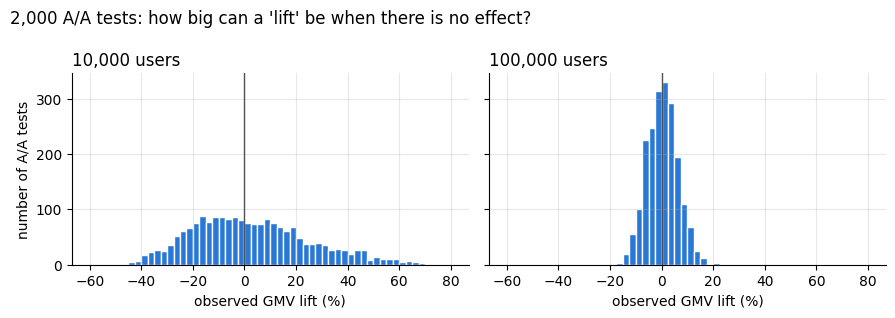

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True, sharey=True)
for ax, n in zip(axes, [10_000, 100_000]):
    ax.hist(lifts[("GMV", n)], bins=56, range=(-60, 80), color=BLUE, edgecolor="white", linewidth=1)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.set_title(f"{n:,} users", loc="left")
    ax.set_xlabel("observed GMV lift (%)")
axes[0].set_ylabel("number of A/A tests")
fig.suptitle("2,000 A/A tests: how big can a 'lift' be when there is no effect?", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### What do these results tell us?

**1. Our setup works.** In all four cases, the false positive rate is close to 5% (between 4.5% and 5.3%; small differences come from the simulation itself). When there is no effect, our test says "significant" about 1 in 20 times, as expected. This also shows that the z-test works well for GMV, even though GMV is very skewed.

**2. More users do not reduce false positives.** The false positive rate is about 5% with both 10,000 and 100,000 users. The test already takes the sample size into account: with fewer users the noise band is wider, so the test asks for a bigger difference before it says "significant". *(This is only true if we look at the result once, at the end of the experiment. Checking it every day — "peeking" — is a different problem, and we will cover it in a later part.)*

**3. One experiment already tells us the size of the noise.** With 100,000 users, 95% of the GMV lifts in 2,000 tests fall between −11% and +12%. This is very close to the noise band we calculated from a single experiment (±11.8%). So we don't need to run 2,000 A/A tests every time: the noise band of one experiment gives us a good estimate.

### Why does this matter?

Imagine that our new feature really increases GMV by **5%**. With 10,000 users, this real effect is completely hidden inside the noise. Even with 100,000 users, it is still smaller than the normal noise range.

So how can we fight this noise? The first option is to collect more users, but this is expensive: to cut the noise in half, we need **four times more users**. The second option is to **reduce the variance** itself. We will look at both options in the next part.

> **Note:** Here the unit of assignment (the user) and the unit of analysis (the user's CR and GMV) are the same. This matters: if we assign users but analyse sessions or orders, the observations are no longer independent and the z-test gives wrong p-values.

---

## Summary — the decisions we made in this part

| Decision | Why |
|---|---|
| Use `md5` (or Murmur/xxHash) for assignment — not `hash()` | Determinism: the same result in every process, server and language |
| Recalculate the assignment instead of storing it | Stateless and scalable; the same function can also be used in analysis |
| A separate salt for each experiment (generated from the experiment ID) | Independent assignments: effects of other experiments are balanced between the groups instead of biasing one of them (it does not remove interactions or carry-over effects) |
| An SRM check for every experiment (`p < 0.001`) | Catch assignment bugs before the analysis |
| Test the assignment with an A/A test on the real metrics | Balanced group sizes are not enough; the groups must also behave the same |
| Read every lift together with its noise band | The higher the variance of a metric, the wider the band |
| More users do not reduce false positives; they reduce noise | `alpha` sets the false positive rate; sample size and variance set how small an effect we can see |
| Same unit for assignment and analysis (the user) | Otherwise observations are not independent and p-values are wrong |

**Next part:** We ended this part with a problem: a real +5% GMV effect can be hidden inside the noise, even with 100,000 users. In the next part, we will try to solve it:

- **Sample size:** How many users do we need to see an effect of a given size?
- **Peeking:** Why can't we just check the results every day and stop when they look good?
- **Variance reduction:** How can we use the users' past data to measure the same effect with fewer users?